# Planejamento de Capacidade de Servidores — Problema 3
**Métodos Numéricos · 2ª GQ · Ciência da Computação · UNICAP**

Neste notebook, analisamos os dados históricos de armazenamento, construímos uma aproximação polinomial quadrática pelo **Método dos Mínimos Quadrados**, calculamos os coeficientes por **Eliminação de Gauss** e estimamos quando as capacidades de armazenamento serão ultrapassadas.

## 1. Problema e dados
O arquivo `armazenamento.csv` contém o volume de armazenamento (TB) observado nos meses 1 a 12. A capacidade atual é **600 TB**; o arquivo `expansoes.csv` informa capacidades adicionais dos planos A, B e C.

**Perguntas do enunciado:** (a) determinar e justificar uma função de crescimento; (b) estimar o próximo mês; (c) identificar o primeiro mês acima de 600 TB; (d) identificar o primeiro mês acima da capacidade de cada plano.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from metodos_capacidade import (ler_armazenamento, ler_expansoes,
    montar_equacoes_normais, ajustar_quadratico, avaliar_polinomio,
    primeiro_mes_ultrapassagem)

# Funciona quando o Jupyter e iniciado na raiz do projeto ou em notebooks/.
base = Path.cwd()
if not (base / 'data' / 'armazenamento.csv').exists():
    base = base.parent
if not (base / 'data' / 'armazenamento.csv').exists():
    raise FileNotFoundError('Abra o notebook a partir da raiz ou da pasta notebooks/ do projeto')
meses, volumes = ler_armazenamento(base / 'data' / 'armazenamento.csv')
planos = ler_expansoes(base / 'data' / 'expansoes.csv')
print('Mes | Armazenamento (TB)')
for m, y in zip(meses, volumes):
    print(f'{int(m):>3} | {y:>8.2f}')
print('\nExpansoes adicionais (TB):', planos)

Mes | Armazenamento (TB)
  1 |   137.99
  2 |   150.45
  3 |   172.59
  4 |   199.09
  5 |   219.06
  6 |   250.06
  7 |   292.32
  8 |   328.07
  9 |   366.12
 10 |   417.17
 11 |   464.15
 12 |   519.14

Expansoes adicionais (TB): {'A': 100.0, 'B': 200.0, 'C': 300.0}


## 2. Item (a): análise dos dados históricos

### Por que analisar as diferenças antes de definir a função?

Queremos representar matematicamente o crescimento do armazenamento. Antes de escolher a forma da função, precisamos responder a duas perguntas:

1. **Quanto o armazenamento aumenta de um mês para o seguinte?** A **primeira diferença** responde a essa pergunta.
2. **Esses aumentos mensais permanecem iguais ou mudam com o tempo?** A **segunda diferença** permite examinar a variação entre os acréscimos.

As duas análises são complementares. As primeiras diferenças mostram se o crescimento mensal é constante ou variável; as segundas permitem verificar se os acréscimos mudam de forma regular, como acontece em um polinômio quadrático exato: **suas segundas diferenças são constantes quando os meses estão igualmente espaçados**. **Nenhuma delas, isoladamente, prova que o crescimento real é quadrático.**

### Passo 1 — Primeiras diferenças: quanto aumentou de um mês para outro?

Denotamos por $y_i$ o armazenamento observado no mês $i$. A primeira diferença é:

$$\Delta y_i=y_{i+1}-y_i.$$

Nos **dados originais** do arquivo `armazenamento.csv`, os três primeiros valores são:

| Mês | Armazenamento observado |
|:--:|--:|
| 1 | 137,99 TB |
| 2 | 150,45 TB |
| 3 | 172,59 TB |

Calculamos os dois primeiros acréscimos:

$$\Delta y_1=y_2-y_1=150{,}45-137{,}99=\boxed{12{,}46\ \text{TB}}$$

$$\Delta y_2=y_3-y_2=172{,}59-150{,}45=\boxed{22{,}14\ \text{TB}}$$

Portanto, **12,46 TB** é o aumento entre os meses **1 e 2**, enquanto **22,14 TB** é o aumento entre os meses **2 e 3**. Repetiremos essa subtração para todos os meses consecutivos.

### Passo 2 — Segundas diferenças: quanto mudou o acréscimo?

Depois de calcular os acréscimos mensais, queremos saber se eles próprios aumentam, diminuem ou permanecem constantes. Para isso, subtraímos duas primeiras diferenças consecutivas:

$$\Delta^2 y_i=\Delta y_{i+1}-\Delta y_i.$$

Usando os valores **já obtidos no passo 1**:

$$\Delta^2 y_1=\underbrace{22{,}14}_{\text{aumento dos meses 2 a 3}}-\underbrace{12{,}46}_{\text{aumento dos meses 1 a 2}}=\boxed{9{,}68\ \text{TB}}$$

Isso significa que o aumento entre os meses 2 e 3 foi **9,68 TB maior** que o aumento entre os meses 1 e 2. Uma segunda diferença **positiva** indica aumento do acréscimo; uma **negativa**, diminuição do acréscimo. Não significa necessariamente que o armazenamento total tenha diminuído.

### Passo 3 — Qual propriedade do polinômio quadrático estamos investigando?

**Propriedade:** quando avaliamos um polinômio de grau 2 em meses consecutivos (intervalos iguais a 1), **as segundas diferenças são constantes**. Vamos demonstrar isso, em vez de apenas afirmar.

Partimos da forma geral de um polinômio quadrático, ainda sem conhecer seus coeficientes:

$$P(m)=a_0+a_1m+a_2m^2,\qquad a_2\ne 0.$$

A primeira diferença do próprio polinômio é:

$$\begin{aligned}
\Delta P(m)&=P(m+1)-P(m)\\
&=[a_0+a_1(m+1)+a_2(m+1)^2]-[a_0+a_1m+a_2m^2]\\
&=a_1+2a_2m+a_2.
\end{aligned}$$

Agora calculamos a segunda diferença:

$$\begin{aligned}
\Delta^2P(m)&=\Delta P(m+1)-\Delta P(m)\\
&=[a_1+2a_2(m+1)+a_2]-[a_1+2a_2m+a_2]\\
&=\boxed{2a_2}.
\end{aligned}$$

O resultado **não depende do mês $m$**: como $a_2$ é um coeficiente fixo, $2a_2$ é constante. Essa é a propriedade matemática que motivou o cálculo das segundas diferenças.

**Exemplo simples:** para $Q(m)=100+10m+2m^2$, os valores nos meses 1 a 5 são $112,128,148,172,200$. As primeiras diferenças são $16,20,24,28$; as segundas são $4,4,4$, exatamente $2a_2=2\cdot2=4$.

### Passo 4 — O que vamos verificar nos 12 meses reais?

Se os dados fossem gerados exatamente por uma função linear, as **primeiras diferenças** seriam constantes. Se fossem gerados exatamente por uma função quadrática, as **segundas diferenças** seriam constantes. Nos dados observados, porém, pode haver oscilações: **segundas diferenças não constantes não impedem o uso de um ajuste quadrático por Mínimos Quadrados**, mas mostram que ele é uma aproximação, não uma igualdade exata.

Vamos calcular as duas diferenças para os 12 meses e visualizar três gráficos: armazenamento total, acréscimos mensais e variação dos acréscimos.


Intervalo | Primeira diferença (TB) | Segunda diferença (TB)
 1–2      |                  12.46 |                     —
 2–3      |                  22.14 |                  9.68
 3–4      |                  26.50 |                  4.36
 4–5      |                  19.97 |                 -6.53
 5–6      |                  31.00 |                 11.03
 6–7      |                  42.26 |                 11.26
 7–8      |                  35.75 |                 -6.51
 8–9      |                  38.05 |                  2.30
 9–10     |                  51.05 |                 13.00
10–11     |                  46.98 |                 -4.07
11–12     |                  54.99 |                  8.01

As segundas diferenças oscilam e não são constantes.


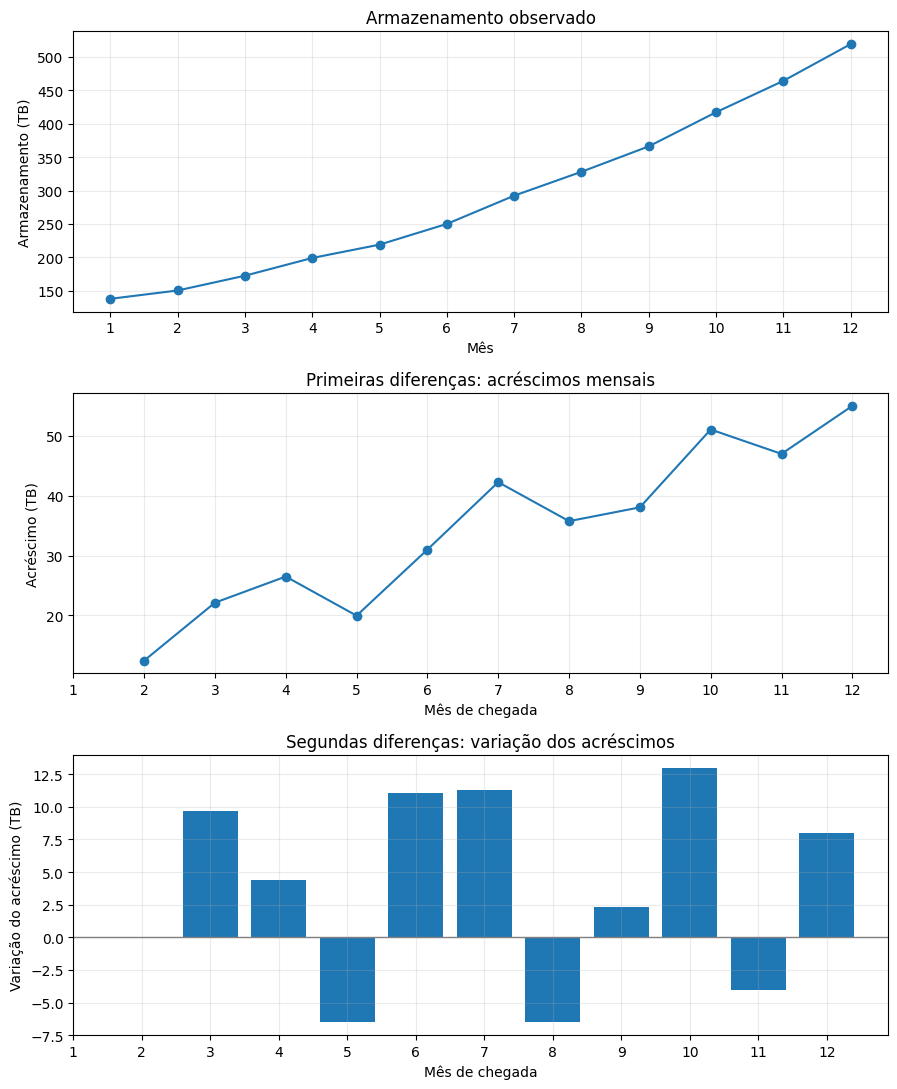

In [2]:
# Diferenças calculadas exclusivamente a partir dos dados observados
primeiras = [volumes[i + 1] - volumes[i] for i in range(len(volumes) - 1)]
segundas = [primeiras[i + 1] - primeiras[i] for i in range(len(primeiras) - 1)]

print('As primeiras diferenças são os acréscimos de um mês para o seguinte.')
print('As segundas diferenças comparam acréscimos consecutivos.')
print('Na linha 2–3, por exemplo, a segunda diferença compara 2–3 com 1–2.\n')
print('Intervalo | Primeira diferença (TB) | Segunda diferença (TB)')
for i, acrescimo in enumerate(primeiras):
    segunda = f'{segundas[i-1]:.2f}' if i >= 1 else '—'
    print(f'{int(meses[i]):>2}–{int(meses[i+1]):<2}     | {acrescimo:>22.2f} | {segunda:>21}')

print('\nAs segundas diferenças oscilam e não são constantes.')

# Cada gráfico responde a uma pergunta diferente sobre os dados.
fig, eixos = plt.subplots(3, 1, figsize=(9, 11))

# 1) Quanto armazenamento foi observado em cada mês?
eixos[0].plot(meses, volumes, 'o-')
eixos[0].set(title='Armazenamento observado', xlabel='Mês', ylabel='Armazenamento (TB)')

# 2) Quanto o armazenamento aumentou de um mês para o seguinte?
eixos[1].plot(meses[1:], primeiras, 'o-')
eixos[1].set(title='Primeiras diferenças: acréscimos mensais', xlabel='Mês de chegada', ylabel='Acréscimo (TB)')

# 3) Quanto cada acréscimo mudou em relação ao acréscimo anterior?
eixos[2].bar(meses[2:], segundas)
eixos[2].axhline(0, linewidth=1, color='gray')
eixos[2].set(title='Segundas diferenças: variação dos acréscimos', xlabel='Mês de chegada', ylabel='Variação do acréscimo (TB)')

for eixo in eixos:
    eixo.set_xticks(meses)
    eixo.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(base / 'resultados' / 'analise_diferencas.png', dpi=150)
plt.show()

### 2.1. Interpretação das diferenças e escolha da aproximação quadrática

**O que mostram as primeiras diferenças?** O acréscimo entre os meses 1 e 2 foi de **12,46 TB**; entre os meses 11 e 12, foi de **54,99 TB**. A média dos cinco primeiros acréscimos é de aproximadamente **22,41 TB**, enquanto a média dos cinco últimos é de **45,36 TB**. Os acréscimos variam, mas apresentam uma tendência geral de aumento. Por isso, um crescimento com taxa constante não descreve diretamente o comportamento observado.

**O que acrescentam as segundas diferenças?** Elas verificam se os acréscimos mudam de forma regular. Como demonstrado acima, em um polinômio quadrático exato com meses consecutivos, a segunda diferença é sempre $2a_2$, independentemente do mês. No gráfico, há valores positivos e negativos, sem constância. Assim, os dados **não seguem exatamente** a propriedade de segundas diferenças constantes de um polinômio quadrático. Essa análise é útil justamente para distinguir uma tendência de uma lei exata.

**Por que a aproximação quadrática é razoável?** O gráfico do armazenamento apresenta curvatura crescente, e as primeiras diferenças indicam acréscimos geralmente maiores nos meses finais. Uma função com termo quadrático consegue representar uma inclinação que aumenta com o tempo, usando apenas três coeficientes:

$$\boxed{P(m)=a_0+a_1m+a_2m^2}.$$

Aqui, $m$ é o mês, $P(m)$ é o armazenamento estimado (TB), e $a_0$, $a_1$ e $a_2$ **ainda serão calculados**. Adotamos o grau 2 como **hipótese de aproximação**, não como uma consequência obrigatória das diferenças.

**Próximo passo.** Aplicaremos o Método dos Mínimos Quadrados para determinar esses coeficientes. Primeiro construiremos a função soma dos quadrados dos resíduos; depois desenvolveremos as derivadas parciais, obteremos as equações normais e resolveremos o sistema por Eliminação de Gauss.

### 2.2. Dedução das equações normais e cálculo dos coeficientes

**Passo 1 — Definir a função a minimizar.** Para os 12 registros, a soma dos quadrados dos resíduos é:

$$S(a_0,a_1,a_2)=\sum_{i=1}^{12}(y_i-a_0-a_1m_i-a_2m_i^2)^2.$$

**Passo 2 — Derivar em relação a cada coeficiente e igualar a zero.** Buscamos um ponto de mínimo de $S$:

$$\frac{\partial S}{\partial a_0}=-2\sum_{i=1}^{12}(y_i-a_0-a_1m_i-a_2m_i^2)=0,$$

$$\frac{\partial S}{\partial a_1}=-2\sum_{i=1}^{12}m_i(y_i-a_0-a_1m_i-a_2m_i^2)=0,$$

$$\frac{\partial S}{\partial a_2}=-2\sum_{i=1}^{12}m_i^2(y_i-a_0-a_1m_i-a_2m_i^2)=0.$$

**Passo 3 — Distribuir as somas e organizar os termos desconhecidos.** Dividindo cada expressão por $-2$ e reunindo os termos com $a_0$, $a_1$ e $a_2$, obtemos:

$$12a_0+a_1\sum m_i+a_2\sum m_i^2=\sum y_i,$$

$$a_0\sum m_i+a_1\sum m_i^2+a_2\sum m_i^3=\sum m_iy_i,$$

$$a_0\sum m_i^2+a_1\sum m_i^3+a_2\sum m_i^4=\sum m_i^2y_i.$$

**Agora podemos concluir** que obtivemos **três equações lineares**, porque as incógnitas $a_0$, $a_1$ e $a_2$ aparecem somente na primeira potência. Essas são as *equações normais* do ajuste quadrático por Mínimos Quadrados.

**Passo 4 — Escrever o sistema na forma matricial.**

$$\underbrace{\begin{bmatrix}12&\sum m_i&\sum m_i^2\\\sum m_i&\sum m_i^2&\sum m_i^3\\\sum m_i^2&\sum m_i^3&\sum m_i^4\end{bmatrix}}_{A}\underbrace{\begin{bmatrix}a_0\\a_1\\a_2\end{bmatrix}}_{\mathbf{x}}=\underbrace{\begin{bmatrix}\sum y_i\\\sum m_iy_i\\\sum m_i^2y_i\end{bmatrix}}_{\mathbf{b}}.$$

**Passo 5 — Calcular com os dados reais.** A próxima célula calcula as somas dos 12 registros, mostra a matriz $A$ e o vetor $\mathbf{b}$ com valores numéricos e resolve $A\mathbf{x}=\mathbf{b}$ pela **Eliminação de Gauss com pivotamento parcial**. Só depois apresentamos os valores dos coeficientes e a função ajustada.


In [3]:
A, b = montar_equacoes_normais(meses, volumes)
print('Matriz A das equacoes normais:')
for linha in A:
    print('  ', '  '.join(f'{valor:12.2f}' for valor in linha))
print('Vetor b:', [round(v, 4) for v in b])
coeficientes = ajustar_quadratico(meses, volumes)
a0, a1, a2 = coeficientes
print('\nCOEFICIENTES DO AJUSTE QUADRATICO:')
print(f'a0 = {a0:.8f}')
print(f'a1 = {a1:.8f}')
print(f'a2 = {a2:.8f}')
print(f'\nP(m) = {a0:.8f} + {a1:.8f}m + {a2:.8f}m²')

Matriz A das equacoes normais:
          12.00         78.00        650.00
          78.00        650.00       6084.00
         650.00       6084.00      60710.00
Vetor b: [3516.21, 27821.59, 257568.39]

COEFICIENTES DO AJUSTE QUADRATICO:
a0 = 125.14568182
a1 = 9.92926823
a2 = 1.90765984

P(m) = 125.14568182 + 9.92926823m + 1.90765984m²


### 2.3. Gráfico dos dados e da aproximação quadrática
O gráfico mostra os 12 valores observados e **a curva quadrática ajustada**. O modelo aproxima a tendência; não é necessário que passe exatamente por cada ponto.

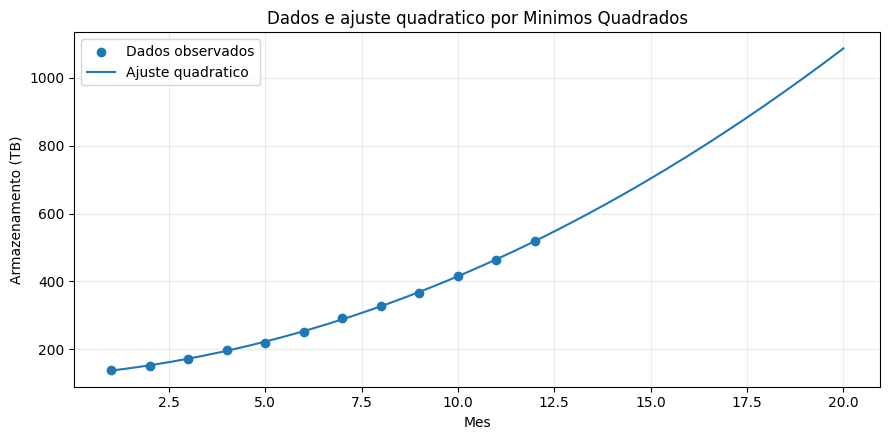

In [4]:
xs = [1 + k*0.1 for k in range(191)]
fig, ax = plt.subplots(figsize=(9,4.5))
ax.scatter(meses, volumes, label='Dados observados', zorder=3)
ax.plot(xs, [avaliar_polinomio(coeficientes,x) for x in xs], label='Ajuste quadratico')
ax.set(xlabel='Mes', ylabel='Armazenamento (TB)', title='Dados e ajuste quadratico por Minimos Quadrados')
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(base / 'resultados' / 'ajuste_quadratico.png', dpi=150)
plt.show()

## 3. Item (b): armazenamento estimado no próximo mês
O último registro é o mês 12. Portanto, o próximo é o **mês 13**. Basta substituir $m=13$ na função ajustada. Essa estimativa é uma **extrapolação**, pois o mês 13 não pertence aos dados observados.

In [5]:
previsao = avaliar_polinomio(coeficientes,13)
print(f'P(13) = {previsao:.2f} TB')

P(13) = 576.62 TB


## 4. Itens (c) e (d): primeiro mês acima de cada capacidade
O enunciado pede o **primeiro mês inteiro** em que a demanda estimada **ultrapassa** uma capacidade $C$:

$$P(m)>C.$$

Por isso, **não precisamos calcular raízes**: avaliamos a função nos meses inteiros seguintes a 12 até encontrar o primeiro valor estritamente maior que o limite. Para cada resultado, verificamos também que o mês anterior ainda não ultrapassava o limite.

- Capacidade atual: 600 TB.
- Planos: capacidade total = 600 TB + capacidade adicional informada no CSV.

Essa avaliação mês a mês é uma verificação direta do modelo ajustado, **não um novo método numérico**.

In [6]:
capacidades = {'Atual':600.0, **{f'Plano {nome}':600.0+extra for nome,extra in planos.items()}}
linhas_resultados=[]
print('Limite          | Capacidade | Primeiro mes | Demanda prevista | Mes anterior')
for nome,capacidade in capacidades.items():
    mes,demanda = primeiro_mes_ultrapassagem(coeficientes,capacidade,ultimo_mes_observado=12)
    anterior = avaliar_polinomio(coeficientes,mes-1)
    assert anterior <= capacidade < demanda
    linhas_resultados.append((nome,capacidade,mes,demanda,anterior))
    print(f'{nome:<15} | {capacidade:>9.0f} TB | {mes:>12} | {demanda:>13.2f} TB | {anterior:>10.2f} TB')
import csv
with (base/'resultados'/'previsoes_capacidade.csv').open('w',newline='',encoding='utf-8') as arq:
    w=csv.writer(arq)
    w.writerow(['limite','capacidade_tb','primeiro_mes_ultrapassagem','demanda_tb','demanda_mes_anterior_tb'])
    w.writerows(linhas_resultados)

Limite          | Capacidade | Primeiro mes | Demanda prevista | Mes anterior
Atual           |       600 TB |           14 |        638.06 TB |     576.62 TB
Plano A         |       700 TB |           15 |        703.31 TB |     638.06 TB
Plano B         |       800 TB |           17 |        845.26 TB |     772.37 TB
Plano C         |       900 TB |           18 |        921.95 TB |     845.26 TB


## 5. Discussão e limitações
A análise das primeiras diferenças mostra acréscimos mensais geralmente crescentes, embora irregulares. As segundas diferenças não são constantes; por isso, o polinômio quadrático é uma hipótese de aproximação, não uma lei exata demonstrada pelos dados. Seus coeficientes foram determinados por Mínimos Quadrados, mediante um sistema linear resolvido por Gauss. As previsões de ultrapassagem resultam da avaliação direta dessa função em meses inteiros.

**Limitações:** o ajuste utiliza apenas 12 meses; o comportamento futuro pode mudar por políticas de retenção, novos usuários ou mudanças de infraestrutura. Assim, os meses estimados **não são garantias** e devem ser revistos quando houver novos dados.

A Eliminação de Gauss determina os coeficientes numericamente; isso não elimina a incerteza de prever o futuro a partir de dados históricos.

## 6. Conclusão
O projeto respondeu aos quatro itens utilizando **um ajuste quadrático por Mínimos Quadrados** e **Eliminação de Gauss** para determinar seus três coeficientes. O modelo estima o armazenamento do mês 13 e identifica, por avaliação em meses inteiros, a primeira ultrapassagem da capacidade atual e de cada plano de expansão.

## 7. Referências bibliográficas
- RUGGIERO, Márcia A. Gomes; LOPES, Vera Lúcia da Rocha. *Cálculo Numérico: Aspectos Teóricos e Computacionais*. 2. ed. São Paulo: Makron Books. Capítulos sobre sistemas lineares e ajuste de curvas por Mínimos Quadrados.
- Material da disciplina de Métodos Numéricos (UNICAP): **Aula 11 — Eliminação de Gauss**; **Aula 15 — Aproximação Polinomial — Método dos Mínimos Quadrados**.

**Nota:** os dados utilizados são os dois arquivos CSV fornecidos para o Problema 3.